# Menús de screening: IC, participación y ejecución

## Resumen
En el ejemplo sintético de dos tipos, el menú estrictamente implementable produce beneficio esperado 0.6249988, frente al mejor contrato único de 0.5000000. La mejora no es universal: desaparece cuando es óptimo excluir al tipo bajo. Un menú débilmente IC puede fallar con desempates adversos; la participación falla si el tipo bajo está mal especificado. No es evidencia de originación real, default o contratos contingentes al flujo. S2 del componente estático, no del programa completo.

## Tres ideas y decisión
Se compararon extender AR con HAC, invertir inferencia RD y abrir un componente estático de screening en el programa microeconómico S1. Se eligió el tercero para rotar de econometría a diseño de mecanismos y hacer explícitas restricciones IC/IR. Método clásico; contribución incremental auditada, no algoritmo nuevo.

## Modelo económico y alcance

Dos tipos privados $0<\theta_L<\theta_H$, probabilidad p del alto, utilidad cuasilineal $u_\theta(q,t)=\theta q-t$, opción externa0. Principal ofrece $(q_L,t_L),(q_H,t_H)$, coste real $cq^2/2$, sin competencia o presupuestos. q es cantidad/capacidad normalizada de servicio, t transferencia normalizada; no son tasas de interés o PD.

IR: $\theta_iq_i-t_i\ge0$. IC: $\theta_iq_i-t_i\ge\theta_iq_j-t_j$. Beneficio $\Pi=(1-p)(t_L-cq_L^2/2)+p(t_H-cq_H^2/2)$. No se modelan ventas inciertas, impago, moral hazard o flujo contingente. El programa original sigue teniendo esas brechas.

In [1]:
import json,csv
from pathlib import Path
import numpy as np
from IPython.display import display,Image
from src.screening import Economy,analytic,uniform,profit,slacks,strictify,qp,realized
root=Path.cwd()
r=json.loads((root/"results/summary.json").read_text())
print(json.dumps(r["config"],ensure_ascii=False,indent=2))

{
  "seed": 20261026,
  "anchor": {
    "low": 1,
    "high": 2,
    "p": 0.2,
    "cost": 1
  },
  "probabilities": [
    0.05,
    0.1,
    0.2,
    0.3,
    0.4,
    0.49,
    0.5,
    0.7,
    0.9
  ],
  "costs": [
    0.5,
    1,
    2
  ],
  "type_pairs": [
    [
      1,
      2
    ],
    [
      0.8,
      2
    ],
    [
      1,
      1.5
    ]
  ],
  "epsilon": 1e-06,
  "solver_tolerance": 1e-07,
  "hypothesis": "Anchor strict menu profit >=1.2*best uniform; IC/IR slack >=-1e-8; QP profit gap<=1e-7 on declared grid. No universal gain claimed.",
  "stress_true_low": 0.8
}


## Derivación de la solución

Sumar IC implica $q_H\ge q_L$. Para cantidades monótonas, transferencias máximas con IR baja e IC alta vinculantes: $t_L=\theta_Lq_L$, $t_H=\theta_Hq_H-(\theta_H-\theta_L)q_L$. Sustituir reduce el objetivo a una cuadrática cóncava separable. Por ello

$$q_H=\theta_H/c,\quad q_L=\max\{0,[\theta_L-p(\theta_H-\theta_L)/(1-p)]/c\}.$$

La monotonía se cumple automáticamente y la concavidad garantiza optimalidad global en **este modelo**. La renta del alto es $(\theta_H-\theta_L)q_L$; el bajo recibe cero. Es un mecanismo débilmente IC con equilibrio veraz, no elección única.

In [2]:
e=Economy(**r["config"]["anchor"])
a=analytic(e)
num,iterations=qp(e)
print("qL,qH,tL,tH:",a)
print("IC/IR:",slacks(a,e))
print("Beneficio",profit(a,e),"Oráculo QP",profit(num,e),"Iteraciones",iterations)
assert abs(profit(a,e)-profit(num,e))<1e-7

qL,qH,tL,tH: [0.75 2.   0.75 3.25]
IC/IR: [0.   0.75 1.25 0.  ]
Beneficio 0.625 Oráculo QP 0.625 Iteraciones 8.0


## Baseline optimizado
Un solo contrato puede servir a ambos tipos o solo al alto. Dentro de cada región se optimizan cantidad y transferencia, luego se escoge el mejor; no usar un precio arbitrario para inflar la mejora. El valor débilmente implementable es el máximo entre θL²/(2c) y pθH²/(2c). Un descuento ε permite participación estricta sin alterar materialmente la comparación.

In [3]:
kind,b,bp=uniform(e)
s=strictify(a,e,r["config"]["epsilon"])
print("Mejor contrato único",kind,b,"beneficio",bp)
print("Baseline con descuento",r["anchor"]["uniform_strict_profit"])
print("Menú estricto",s,"beneficio",profit(s,e))
print("Mejora respecto a baseline ideal",profit(s,e)/bp-1)
print("Slacks estrictos",slacks(s,e))

Mejor contrato único pooling [1. 1. 1. 1.] beneficio 0.5
Baseline con descuento 0.499999
Menú estricto [0.75     2.       0.749999 3.249998] beneficio 0.6249988
Mejora respecto a baseline ideal 0.24999759999999993
Slacks estrictos [1.000000e-06 7.500020e-01 1.249999e+00 1.000000e-06]


## Auditoría sobre parámetros
81 economías determinísticas de grilla: 9 probabilidades×3 costes×3 pares de tipos. Cada una conserva asignaciones, transferencias, restricciones y comparación numérica independiente con QP(SLSQP, inicial cero). Es estática comparativa sintética, no muestreo de una población: no inventar errores Monte Carlo o confianza estadística.

In [4]:
rows=list(csv.DictReader((root/"results/grid.csv").open()))
assert len(rows)==81
print("Casos",len(rows),"Máximo error beneficio QP",r["max_qp_profit_gap"],"Error cantidades",r["max_quantity_error"])
assert r["max_qp_profit_gap"]<=r["config"]["solver_tolerance"]
for row in rows:
 if float(row["low"])==1 and float(row["high"])==2 and float(row["cost"])==1:
  print("p",row["p"],"qL",row["qL"],"menú",row["menu_profit"],"baseline",row["baseline_profit"])

Casos 81 Máximo error beneficio QP 4.936051567483446e-13 Error cantidades 1.444968060759777e-06
p 0.05 qL 0.9473684210526315 menú 0.5263157894736842 baseline 0.5
p 0.1 qL 0.8888888888888888 menú 0.5555555555555556 baseline 0.5
p 0.2 qL 0.75 menú 0.625 baseline 0.5
p 0.3 qL 0.5714285714285714 menú 0.7142857142857144 baseline 0.6
p 0.4 qL 0.33333333333333326 menú 0.8333333333333335 baseline 0.8
p 0.49 qL 0.03921568627450989 menú 0.9803921568627452 baseline 0.98
p 0.5 qL 0.0 menú 1.0 baseline 1.0
p 0.7 qL 0.0 menú 1.4 baseline 1.4
p 0.9 qL 0.0 menú 1.8 baseline 1.8


## Resultados y fallos de implementación
Izquierda: la ventaja de menú desaparece al aumentar p y excluir al bajo. Derecha: elegir contratos y optar por no participar cambia resultados cuando IC/IR son débiles o el tipo real difiere del supuesto.

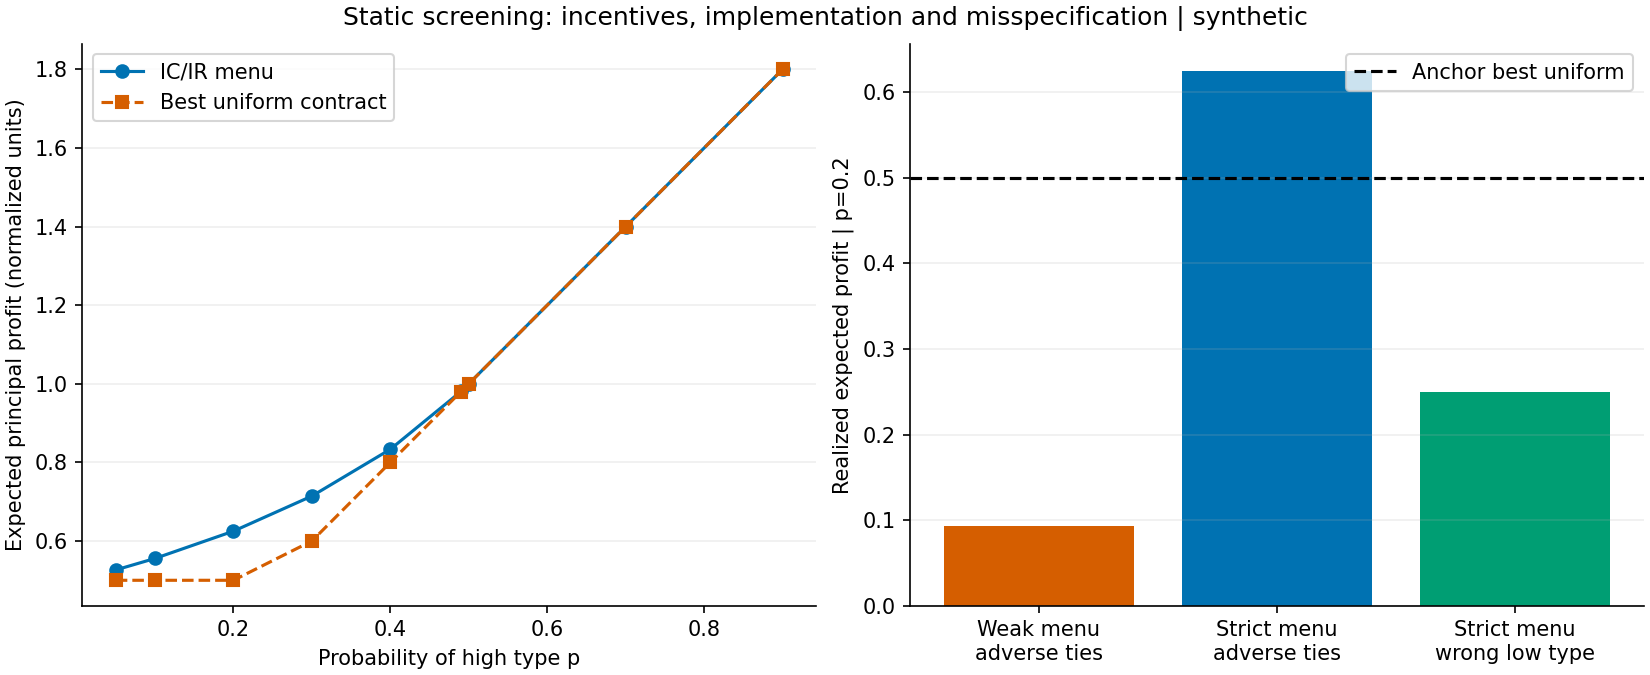

In [5]:
display(Image(filename=str(root/"results/comparison.png")))

## Falsación1: empates de incentivos
Con IC débil el tipo alto puede imitar al bajo sin perder utilidad, y el bajo puede elegir la opción externa. El equilibrio veraz no garantiza selección veraz única. Descuentos ε al contrato bajo y2ε al alto crean márgenes estrictos en el ejemplo sin asignaciones distintas.

In [6]:
for label,menu in [("Débil",a),("Estricto",s)]:
 print(label,"beneficio contable veraz",profit(menu,e),"elección desempate adverso",realized(menu,e,tie="smallest"))
assert abs(realized(s,e,tie="smallest")-profit(s,e))<1e-9

Débil beneficio contable veraz 0.625 elección desempate adverso 0.09375
Estricto beneficio contable veraz 0.6249988 elección desempate adverso 0.6249988


## Falsación2: preferencias mal especificadas
Si el tipo bajo real es0,8 en lugar de1, rechaza el contrato de baja cantidad. La ventaja de beneficio puede desaparecer; comparador con información de tipo real se declara oráculo informado, no un baseline con mismo conjunto informativo.

In [7]:
print("Menú diseñado para θL1, realθL0.8:",realized(s,e,true_low=.8))
true_e=Economy(.8,2,.2,1)
print("Contrato único informado sobre tipo real:",uniform(true_e)[2])
first_best=np.array([1.,2.,1.,4.])
print("Ablation sin IC: beneficio aparente",profit(first_best,e),"slacks",slacks(first_best,e))
print("El first-best sin renta informativa no es implementable: IC alta negativa.")

Menú diseñado para θL1, realθL0.8: 0.24999960000000004
Contrato único informado sobre tipo real: 0.4
Ablation sin IC: beneficio aparente 0.8 slacks [ 0.  0.  2. -1.]
El first-best sin renta informativa no es implementable: IC alta negativa.


## Costes y trazabilidad
Comparación de forma cerrada y QP sobre mismas economías, generación excluida. Memoria Python instrumentada no RSS; no extrapolar servicio real. Seeds solo generan casos de tests/microbenchmark; grilla principal determinística.

In [8]:
print((root/"results/costs.csv").read_text())
print("Versiones",r["versions"])
print("SHA256 datos",r["data_sha256"])
print("SHA256 fuente",r["source_sha256"])

economies,calls,method,seconds,python_peak_bytes
1,3,closed_form,0.00011858299990308296,352
1,3,numerical_QP,0.027439639000021998,73138
10,30,closed_form,0.00018808300001182943,328
10,30,numerical_QP,0.21425072100009857,41504
50,150,closed_form,0.0018429159999868716,648
50,150,numerical_QP,1.8463392940000176,39858

Versiones {'python': '3.12.14', 'numpy': '2.3.5', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
SHA256 datos 2ef1b49e1ee2df4575e058b9639f7faaeb0c5f30468da438b53a57703292420d
SHA256 fuente 37453ea3fc41b2368dab9ec7012cde5bc5bae2057b4fa4136afb5ee578de5431


## Lectura crítica y siguientes pasos
¿Es la utilidad cuasilineal razonable para crédito con liquidez limitada? ¿Cómo cambia IC si se observa flujo con error? ¿Qué restricciones de equidad se necesitan? Este MVP no responde con datos reales: solo aporta un núcleo estático verificado para explorar esas preguntas. Beneficio del principal no equivale a bienestar ni inclusión; qL puede disminuir y el tipo bajo puede quedar excluido.

Cinco referencias reales en referencias.bib, informe de14p y límites del componente. Próximos: presupuesto, más tipos y contingencia de flujo con revelación verificable. Notebook ejecutado en IPython limpio en proceso sin kernel/socket; errores abortan y outputs permanecen guardados.